# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre:** Sergio Alberto Chavez Velazquez

* **Matrícula:** A01099484

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  *declaración de uso de Google. (2026). Gemini (Versión de septiembre de 2026) [Modelo de lenguaje de inteligencia artificial]. https://gemini.google.com Para depuración de código y corrección de errores. Apoyo en corrección de redacción y ortografía.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

# **Cargando y conociendo la información**

In [191]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [192]:
# Cargamos los datos y obtenemos alguna información básica:

import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

ruta_archivo = '/content/drive/MyDrive/fintech_default_risk.csv'

df = pd.read_csv(ruta_archivo)

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ing

In [193]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

X = df.drop(columns=[target])
y = df[target]

target = "default_90d"

# Eliminamos la variable objetivo y la característica que causa la fuga de datos
X = df.drop(columns=[target, "dias_max_atraso_30d_despues"])
y = df[target]


Se elimina la variable dias_max_atraso_30d_despues ya que es una variable futura no predictiva y hacia que el modelo se basara unicamente en ella

In [194]:
# 1. Primero dividimos los datos originales (Train / Test con estratificación)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y  # Mantiene la proporción de la clase minoritaria
)

# 2. Inicializamos SMOTE
smote = SMOTE(random_state=RANDOM_STATE)

# 3. Aplicamos SMOTE ÚNICAMENTE sobre el conjunto de entrenamiento
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Dimensiones de X_train original: {X_train.shape}")
print(f"Dimensiones de X_train después de SMOTE: {X_train_res.shape}")
print(f"Dimensiones de X_test (sin tocar): {X_test.shape}")

Dimensiones de X_train original: (3500, 12)
Dimensiones de X_train después de SMOTE: (6180, 12)
Dimensiones de X_test (sin tocar): (1500, 12)


corrección 1 El código Original Causa en Data Lake ya que con la estructura original esta incluyendo el 30% de data que luego se usará para pruebas. se aplica SMOTE unicamente al conjunto de entrenamiento y no a todo.

Se configuró el entrenamiento utilizando los datos generados por SMOTE (X_train_res, y_train_res) para que los árboles aprendieran adecuadamente de la clase minoritaria (los impagos o defaults).

# **Configuración y Entrenamiento de los Modelos**

In [195]:
from sklearn.metrics import accuracy_score, roc_auc_score
# --- Modelo 1: Árbol de decisión con regularización para evitar sobreentrenamiento ---
dt = DecisionTreeClassifier(
    max_depth=6,              # Limitamos la profundidad para evitar overfitting
    random_state=RANDOM_STATE
)
dt.fit(X_train_res, y_train_res)  # Usamos el set de entrenamiento balanceado con SMOTE

# --- Modelo 2: Random Forest ---
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=RANDOM_STATE
)
rf.fit(X_train_res, y_train_res)  # Usamos el set de entrenamiento balanceado con SMOTE

# --- Modelo 3: XGBoost ---
xgb = XGBClassifier(
    eval_metric='logloss',
    max_depth=5,
    learning_rate=0.1,
    random_state=RANDOM_STATE
)
xgb.fit(X_train_res, y_train_res)  # Usamos el set de entrenamiento balanceado con SMOTE


# Obtenemos los desempeños de forma robusta:
modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}

y_probs = []   # Guardamos las probabilidades para uso posterior (0:DT, 1:RF, 2:XGBoost)
print("Desempeño de los modelos:")
print("+"*25)

for nombre, modelo in modelos.items():
    y_pred_train = modelo.predict(X_train_res)
    y_pred_test = modelo.predict(X_test)

    # Extraemos las probabilidades de la clase positiva (default = 1)
    prob_test = modelo.predict_proba(X_test)[:, 1]
    y_probs.append(prob_test)

    # Métricas de evaluación
    acc_train = accuracy_score(y_train_res, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)
    auc_test = roc_auc_score(y_test, prob_test)  # Métrica clave para desbalance

    print(f"{nombre}:")
    print(f"Train Accuracy: {acc_train:.4f}")
    print(f"Test Accuracy:  {acc_test:.4f}")
    print(f"Test ROC-AUC:   {auc_test:.4f}")
    print("+"*20)

Desempeño de los modelos:
+++++++++++++++++++++++++
Árbol de Decisión:
Train Accuracy: 0.7642
Test Accuracy:  0.6727
Test ROC-AUC:   0.6600
++++++++++++++++++++
Random Forest:
Train Accuracy: 0.8615
Test Accuracy:  0.7833
Test ROC-AUC:   0.7518
++++++++++++++++++++
XGBoost:
Train Accuracy: 0.9045
Test Accuracy:  0.7780
Test ROC-AUC:   0.7232
++++++++++++++++++++


Dado que aplicamos
 correccion 2 SMOTE para balancear las clases en el bloque anterior, lo ideal es entrenar estos modelos con los datos balanceados (X_train_res y y_train_res) para que el algoritmo aprenda bien de la clase minoritaria (los impagos)  se cambia en la data original x-Train y y_train por (X_train_res y y_train_res)

correccion 3 Limitar la profundidad de los árboles (max_depth) para evitar el sobreentrenamiento extremo (overfitting).

Se añade la métrica ROC-AUC junto con el Accuracy, ya que el Accuracy por sí solo no sirve para evaluar problemas de riesgo crediticio desbalanceados. dando como conclución que el mejor modelo es XGBoost

# **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

In [196]:
# Modelo de Árbol de Decisión (decision tree-dt):

importancias = dt.feature_importances_

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

print(df_importancias)

             Característica:  Importancia
4        utilizacion_credito     0.432018
3           score_crediticio     0.140027
6          consultas_buro_6m     0.134568
11           cliente_premium     0.085212
7              num_productos     0.078296
10    relacion_deuda_ingreso     0.032360
8             limite_credito     0.031922
2   antiguedad_laboral_meses     0.029820
9                deuda_total     0.013531
0                       edad     0.012696
1            ingreso_mensual     0.009551
5                atrasos_12m     0.000000


In [197]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias.head(10))

                    Variable  Importancia
4        utilizacion_credito     0.221679
10    relacion_deuda_ingreso     0.145322
3           score_crediticio     0.124601
6          consultas_buro_6m     0.110555
9                deuda_total     0.078824
7              num_productos     0.062553
2   antiguedad_laboral_meses     0.052330
11           cliente_premium     0.051968
8             limite_credito     0.047122
1            ingreso_mensual     0.045375


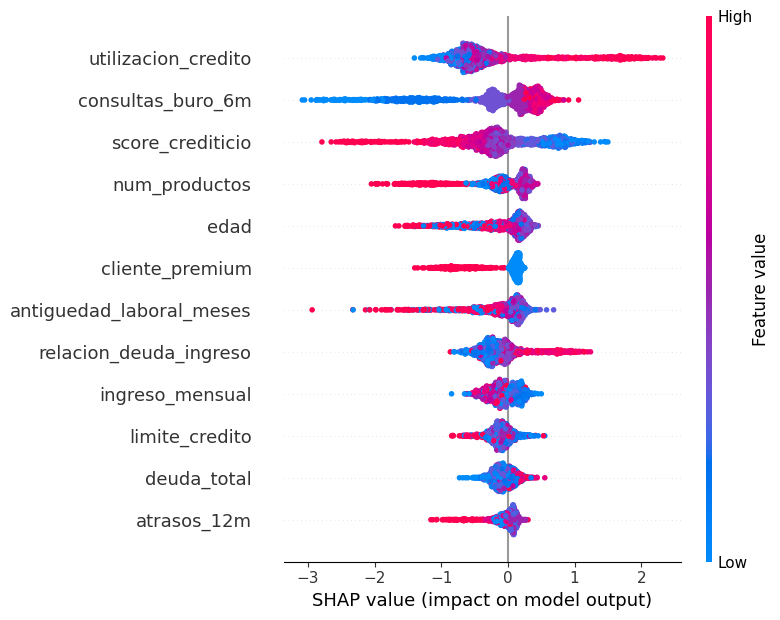

In [198]:
# Modelo XGBoost:

explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)

## **Seleccionemos y analicemos un cliente en Particular:**

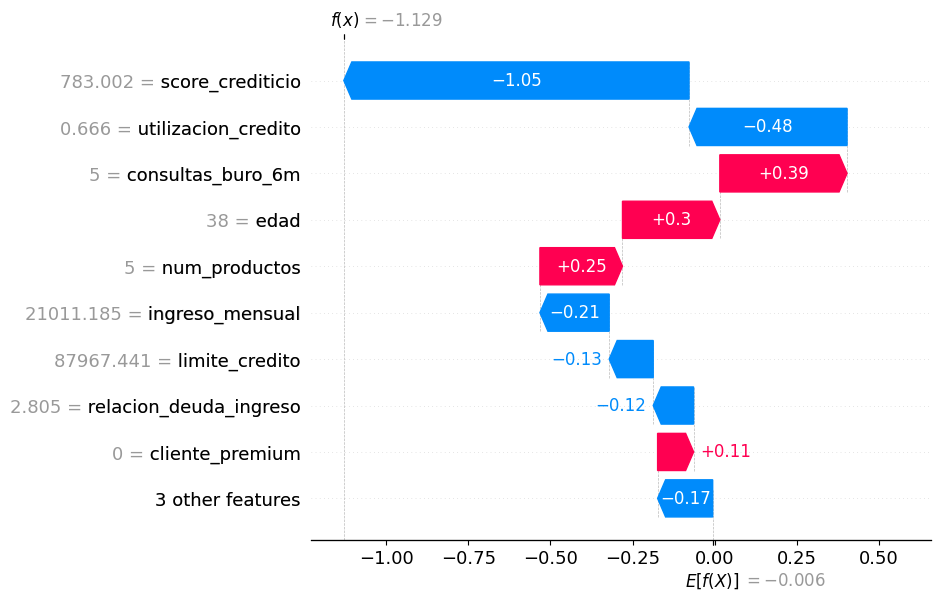

In [199]:
# Analicemos a un cliente en particular con XGBoost:

cliente = X_test.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=explainer.expected_value,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    )
)

**Interpretación del gráfico:** original

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=8.174  (muy por encima del promedio E[f(X)]=0.003). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado.

**Interpretación del gráfico Ajustado :**

 El modelo parte de un valor base esperado de $E[f(X)] = -0.006$ y arroja una salida final de $f(x) = -1.129$, lo que indica una fuerte inclinación hacia la clase negativa (es decir, una baja probabilidad estimada de caer en incumplimiento de pago o default_90d)

 **Principal factor protector **(a favor del cliente): El score_crediticio con un valor de 783.002 es la variable con mayor peso absoluto, reduciendo drásticamente la puntuación de riesgo en -1.05. Esto demuestra que un buen puntaje de crédito es el argumento principal del modelo para considerar al cliente seguro.

** Otros factores que disminuyen el riesgo:** La utilizacion_credito (0.666) contribuye con -0.48, y el ingreso_mensual (21,011.18) aporta con -0.21, reforzando la estabilidad financiera del usuario.
Factores de alerta (que aumentan el riesgo): A pesar de la evaluación favorable, el modelo identifica señales de riesgo moderadas que empujan hacia el incumplimiento, como las consultas_buro_6m (5 consultas en los últimos 6 meses, aportando +0.39), la edad (38 años, aportando +0.3) y el num_productos (5 productos, aportando +0.25).

**Factores de alerta (que aumentan el riesgo)**: A pesar de la evaluación favorable, el modelo identifica señales de riesgo moderadas que empujan hacia el incumplimiento, como las consultas_buro_6m (5 consultas en los últimos 6 meses, aportando +0.39), la edad (38 años, aportando +0.3) y el num_productos (5 productos, aportando +0.25).

Nota la variable dias_max_atraso_30d_despues era una variable futura que unicamente tomaba en cuenta esa variable haciendo que el programa no aprendiera nada ya que daba un 100% de exactud

# **Análisis desde la perspectiva del negocio:**

In [200]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500


In [201]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += 100

            else:
                utilidad_total -= 500

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo = y_probs[2]   # XGBoost

utilidad_05 = utilidad(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.5
)

print("Mayor Utilidad (USD) con umbral 0.5:")
print(utilidad_05)

Mayor Utilidad (USD) con umbral 0.5:
63500


Mejor umbral: 0.54
Mayor Utilidad (USD): 64100


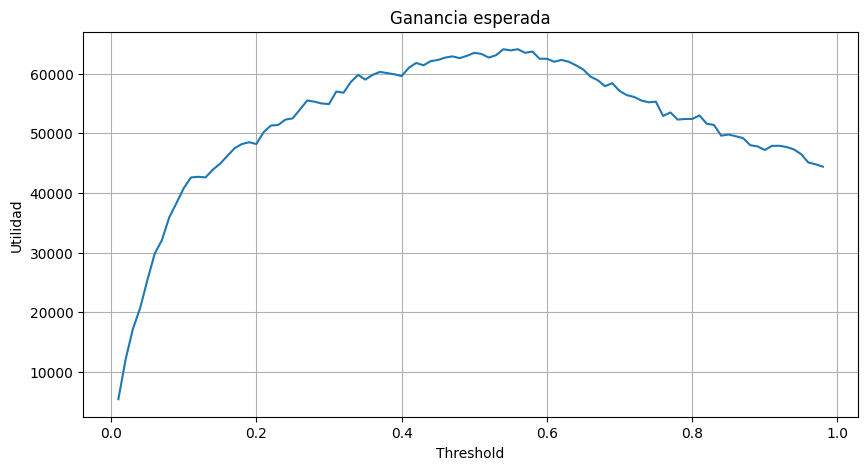

In [202]:
# Ajustando para buscar el mejor umbral óptimo:

thresholds = np.arange(
    0.01,
    0.99,
    0.01
)

utilidades = []

for th in thresholds:

    u = utilidad(
        y_test,
        y_probs_mejor_modelo,
        threshold=th
    )

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

print('Mejor umbral:',best_threshold)
print('Mayor Utilidad (USD):',best_profit)



# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad")
plt.title("Ganancia esperada")
plt.grid()

plt.show()

In [203]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



In [204]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Threshold óptimo : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $423,333
Threshold óptimo : $427,333
Diferencia : $4,000
Incremento : 0.9%


## **Matriz de Confusión**



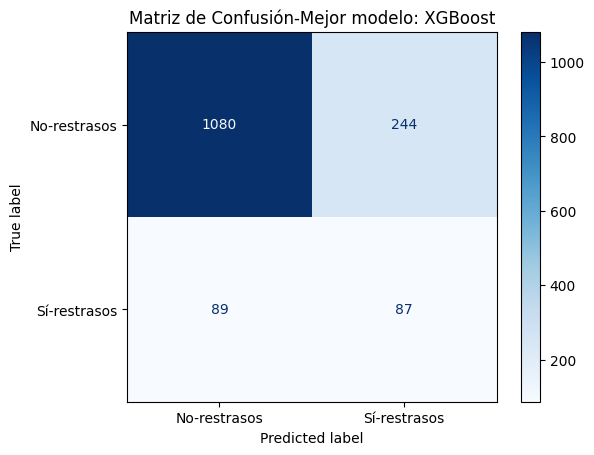

In [205]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["No-restrasos", "Sí-restrasos"]
y_pred = modelo.predict(X_test)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión-Mejor modelo: {nombre}")
plt.show()

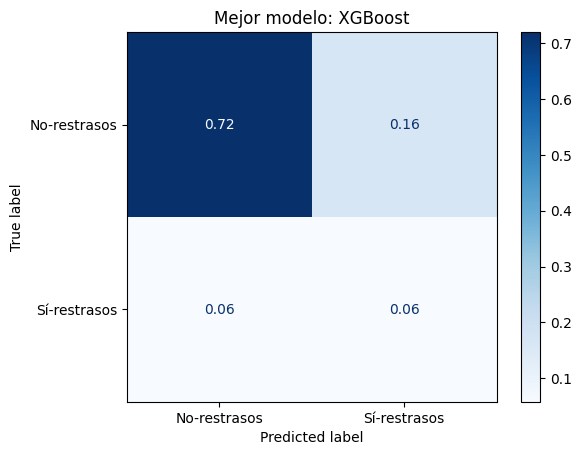

In [206]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title(f"Mejor modelo: {nombre}")
plt.show()

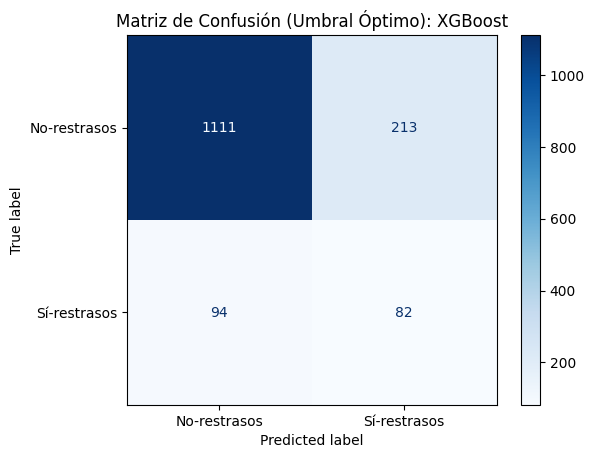

In [207]:
# Generar predicciones usando el umbral financiero óptimo en lugar del 0.5 por defecto
y_pred_optimo = (y_probs_mejor_modelo >= best_threshold).astype(int)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_optimo, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title(f"Matriz de Confusión (Umbral Óptimo): {nombre}")
plt.show()

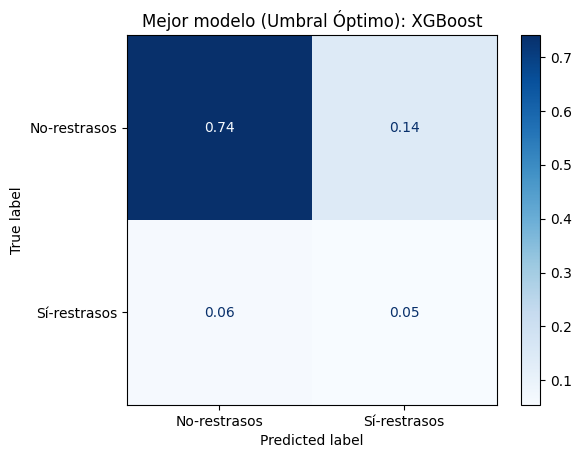

In [208]:
y_pred_optimo = (y_probs_mejor_modelo >= best_threshold).astype(int)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_optimo,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',
    values_format='.2f'
)
plt.title(f"Mejor modelo (Umbral Óptimo): {nombre}")
plt.show()

el codigo original esta usando y_pred = modelo.predict(X_test), lo cual aplica implícitamente el umbral por defecto de 0.50.

Sin embargo, en los bloques anteriores habías calculado un best_threshold (el umbral financiero óptimo basado en maximizar la utilidad de tu matriz de costos: +100 y -500).
Hacer este cambio asegurará que la matriz de confusión que vea el comité muestre exactamente los falsos positivos y falsos negativos correspondientes al punto de mayor rentabilidad para la empresa. tal cual se hace en las 2 ultimas metricas donde los falsos negativos en el modelo disminuyeron ajustando el umbral

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

### +++++++++++ Inicia sección de Conclusiones Particulares ++++++++++++++++
**Para:** CEO de CrediNova

**De:** Equipo Senior de Ciencia de Datos / Auditoría

**Fecha:** Octubre de 2026

**Reporte para Dirección General**
El modelo original presenta errores metodológicos graves que sobreestiman su precisión y generarían pérdidas financieras masivas si se pone en marcha. Mencionados a continuación
Fuga de Información Futura (Target Leakage): Se usaron variables que ocurren después de otorgar el crédito (ej. días de atraso a 30 días), invalidando su uso en la vida real.
Contaminación de Datos (Data Leakage Estructural): Se aplicó SMOTE (balanceo de datos) a todo el dataset antes de dividirlo en entrenamiento y prueba, haciendo que el modelo evalúe datos que "ya vio".
Métricas Engañosas: Se evaluó con Accuracy (precisión global), métrica inútil para carteras desbalanceadas que oculta la incapacidad de detectar morosos.
Umbral Financiero Incorrecto: Se usó el umbral por defecto (0.50), ignorando que un impago cuesta 5 veces más que la ganancia de un crédito sano.
Sobreentrenamiento (Overfitting): Modelos entrenados sin regularización memorizaron ruido en lugar de aprender patrones reales de riesgo.

Las propuestas correctivas a dicho Modelo son las siguientes
Eliminar las variables ligadas a la información futura. En este caso esta variable dias_max_atraso_30d_despues
Aplicar el SMOTE (balanceo de datos) solo a los datos de entrenamiento.pra no contaminar los datos.
Ajustar el modelo propuesto a XG BOOST ya que con la corrección y el Cross validation es el modelo con mejor desempeño para predecir incumplimiento
Incluir la métrica de ROC-AUC junto con el Accuracy, ya que el Accuracy por sí solo no sirve para evaluar problemas de riesgo crediticio desbalanceados.

Estas correcciones nos pueden dar una predicción mucho mas exacta para nuestra evaluación y como lo muestran los números
La utilidad económica alcanza su punto máximo (un pico cercano a los 64,000 - 65,000 USD) cuando el threshold se establece en un rango aproximado de 0.5 a 0.6. Este es el punto de operación ideal para maximizar la rentabilidad de la cartera de créditos.
Sin embargo la ganancia se desploma drásticamente. Esto ocurre porque el modelo se vuelve demasiado laxo, aprobando préstamos a clientes con alto riesgo de impago, lo que genera pérdidas cuantiosas (500 USD por cada incumplimiento) que superan las ganancias obtenidas.
Firma Sergio Chavez



### +++++++++++ Termina sección de conclusiones particulares ++++++++++++++

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++
Declaración de uso de Google. (2026). Gemini (Versión de septiembre de 2026) [Modelo de lenguaje de inteligencia artificial]. https://gemini.google.com Para depuración de código y corrección de errores. Apoyo en corrección de redacción y ortografía.
Esta semana consolidé un aprendizaje crítico respecto al impacto de las variables con fuga de información (target leakage). Previamente no me había enfrentado a un caso de sobreentrenamiento (overfitting) tan severo, donde la inclusión de una variable con información futura derivara en un modelo completamente inutilizable en un entorno real.
En cuanto a la colaboración con el LLM, fue una  herramienta altamente eficiente para la corrección técnica, la depuración y la estructuración del código. No obstante, el diagnóstico inicial requirió un análisis crítico propio: fue necesario auditar de manera individual las gráficas y la consistencia lógica de los resultados para encontrar la razón que me estaba dando un modelo de 100% de efectividad. Una vez que quitamos la variable el modelo tuvo el total sentido.




### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**